# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Pranaja Adyatma Budiman | 5054251009 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 20)

In [2]:
df = pd.read_csv("Mall_Customers.csv")

print("5 baris pertama:")
display(df.head())

print("Jumlah baris dan kolom:", df.shape)

print("\nTipe data:")
print(df.dtypes)

print("\nStatistik deskriptif:")
display(df.describe())

print("\nJumlah missing value per kolom:")
print(df.isna().sum())

print("\nJumlah baris duplikat:", df.duplicated().sum())

5 baris pertama:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Jumlah baris dan kolom: (200, 5)

Tipe data:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Statistik deskriptif:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Jumlah missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah baris duplikat: 0


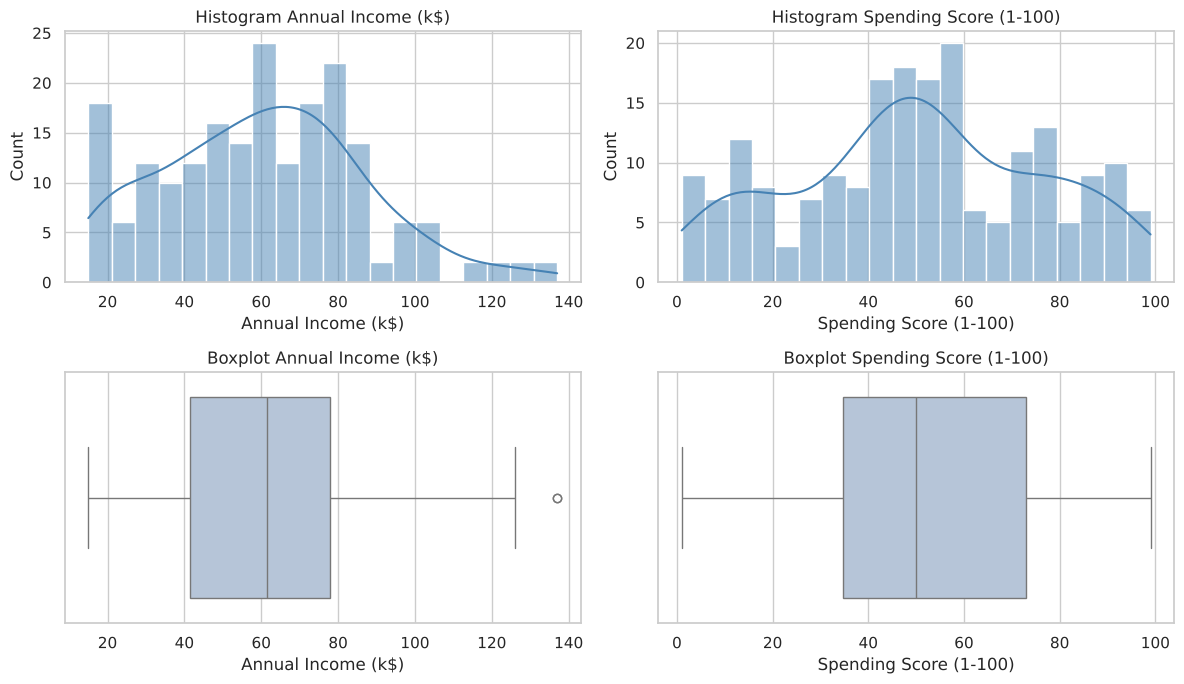

Annual Income (k$): rentang 15 - 137, batas IQR [-13.2, 132.8], jumlah outlier = 2
Spending Score (1-100): rentang 1 - 99, batas IQR [-22.6, 130.4], jumlah outlier = 0


In [3]:
fitur = ["Annual Income (k$)", "Spending Score (1-100)"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, kolom in enumerate(fitur):
    sns.histplot(df[kolom], bins=20, kde=True, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"Histogram {kolom}")
    sns.boxplot(x=df[kolom], ax=axes[1, i], color="lightsteelblue")
    axes[1, i].set_title(f"Boxplot {kolom}")
plt.tight_layout()
plt.show()

# Deteksi outlier sederhana dengan aturan IQR
for kolom in fitur:
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier = df[(df[kolom] < batas_bawah) | (df[kolom] > batas_atas)]
    print(f"{kolom}: rentang {df[kolom].min()} - {df[kolom].max()}, "
          f"batas IQR [{batas_bawah:.1f}, {batas_atas:.1f}], jumlah outlier = {len(outlier)}")

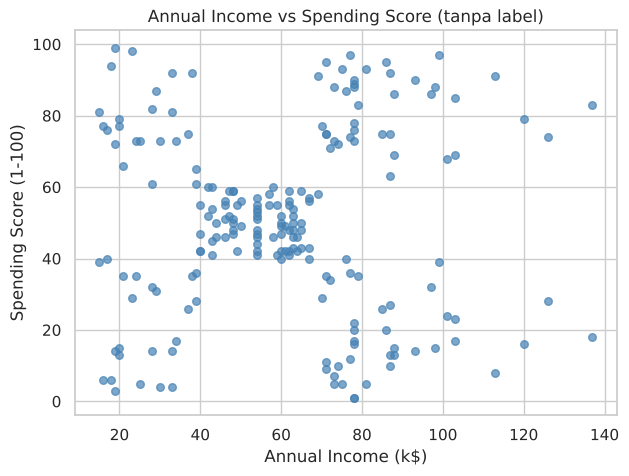

In [4]:
plt.figure(figsize=(7, 5))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], s=30, alpha=0.7, color="steelblue")
plt.title("Annual Income vs Spending Score (tanpa label)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

**Jawaban:**

- **Missing value dan duplikat:** tidak ada. Seluruh 200 baris lengkap (jumlah missing value 0 pada semua kolom) dan jumlah baris duplikat adalah 0.
- **Rentang fitur:** `Annual Income (k$)` berkisar 15 sampai 137 (rata-rata 60,6; median 61,5), distribusinya agak miring ke kanan dan dengan aturan IQR terdapat 2 outlier di sisi atas (pelanggan dengan pendapatan 137 k$). `Spending Score (1-100)` berkisar 1 sampai 99 (rata-rata 50,2; median 50), distribusinya relatif lebar dan tidak memiliki outlier menurut aturan IQR.
- **Kelompok terpisah:** ya. Pada scatter plot terlihat kira-kira lima kelompok: satu kelompok besar di tengah (pendapatan sedang, spending sedang) dan empat kelompok di sudut-sudut (pendapatan rendah/tinggi dikombinasikan dengan spending rendah/tinggi). Kelompok di tengah bersinggungan dengan beberapa kelompok sudut, sehingga batasnya tidak sepenuhnya tegas.

# 2. Preprocessing

In [5]:
# Cek missing value dan duplikat
print("Missing value total:", df.isna().sum().sum())
print("Baris duplikat     :", df.duplicated().sum())

# Penanganan (jika ada). Pada dataset ini tidak ada, tetapi kode tetap aman dijalankan.
df = df.dropna().drop_duplicates().reset_index(drop=True)

# CustomerID (identitas) dan Gender tidak dipakai sebagai fitur clustering
X = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()

print("\nBentuk X:", X.shape)
display(X.head())

Missing value total: 0
Baris duplikat     : 0

Bentuk X: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [6]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

print("Beberapa baris X_scaled:")
display(X_scaled.head())

print("Statistik deskriptif X_scaled:")
display(X_scaled.describe().round(3))

Beberapa baris X_scaled:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


Statistik deskriptif X_scaled:


,Annual Income (k$),Spending Score (1-100)
count,200.000,200.000
mean,-0.000,-0.000
std,1.003,1.003
min,-1.739,-1.910
25%,-0.728,-0.600
50%,0.036,-0.008
75%,0.666,0.885
max,2.918,1.894


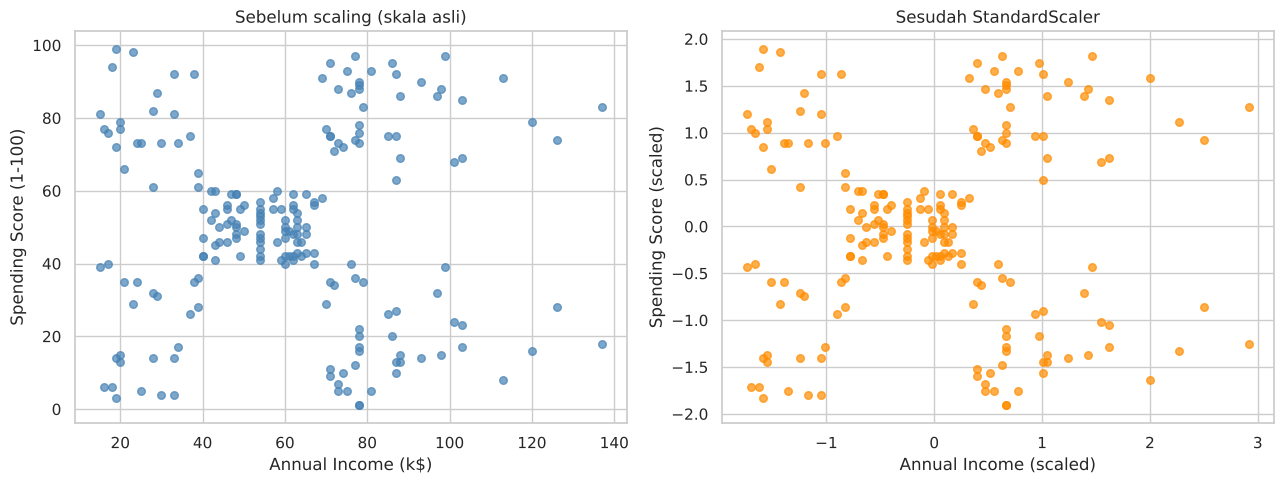

Rentang sebelum scaling:
                         min  max  rentang
Annual Income (k$)       15  137      122
Spending Score (1-100)    1   99       98

Std sebelum scaling:
 Annual Income (k$)        26.26
Spending Score (1-100)    25.82
dtype: float64

Std sesudah scaling:
 Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], s=30, alpha=0.7, color="steelblue")
axes[0].set_title("Sebelum scaling (skala asli)")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")

axes[1].scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], s=30, alpha=0.7, color="darkorange")
axes[1].set_title("Sesudah StandardScaler")
axes[1].set_xlabel("Annual Income (scaled)")
axes[1].set_ylabel("Spending Score (scaled)")
plt.tight_layout()
plt.show()

print("Rentang sebelum scaling:\n", X.agg(["min", "max"]).T.assign(rentang=lambda d: d["max"] - d["min"]))
print("\nStd sebelum scaling:\n", X.std().round(2))
print("\nStd sesudah scaling:\n", X_scaled.std().round(2))

# Penjelasan:
# Income berkisar 15-137 (rentang ~122) sedangkan Spending Score 1-99 (rentang ~98).
# Algoritma berbasis jarak (DBSCAN: eps; BIRCH: threshold) menghitung jarak Euclidean,
# sehingga fitur dengan skala/variansi lebih besar akan mendominasi jarak. Selain itu eps dan
# threshold hanya bermakna jika kedua fitur berada pada skala sebanding. GMM juga berasumsi
# skala yang sebanding agar optimasi kovarians stabil.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

**Alasan pemilihan fitur:** kedua fitur ini bersifat numerik, langsung berkaitan dengan perilaku belanja pelanggan (kemampuan finansial dan kecenderungan membelanjakan uang), dan hanya berjumlah dua sehingga hasil clustering dapat divisualisasikan langsung pada bidang 2 dimensi dan mudah diinterpretasikan. Pada scatter plot awal kedua fitur ini juga sudah menunjukkan struktur kelompok yang jelas.

**Alasan `CustomerID` tidak digunakan:** `CustomerID` hanya nomor identitas urut (1 sampai 200) yang tidak membawa informasi tentang karakteristik pelanggan. Jika dimasukkan, algoritma berbasis jarak akan ikut menghitung selisih nomor ID, sehingga pelanggan dengan ID berdekatan terlihat "mirip" padahal tidak ada hubungannya, dan hal ini hanya menambah noise pada hasil clustering.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

print("Label unik DBSCAN:", np.unique(labels_dbscan))

Label unik DBSCAN: [-1  0  1  2  3  4  5  6]


In [9]:
print("Jumlah anggota tiap label DBSCAN (-1 = noise):")
print(pd.Series(labels_dbscan).value_counts().sort_index())

n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = int((labels_dbscan == -1).sum())

print("\nJumlah cluster (tanpa noise):", n_clusters_dbscan)
print("Jumlah titik noise          :", n_noise_dbscan, f"({n_noise_dbscan / len(labels_dbscan):.1%})")

Jumlah anggota tiap label DBSCAN (-1 = noise):
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

Jumlah cluster (tanpa noise): 7
Jumlah titik noise          : 35 (17.5%)


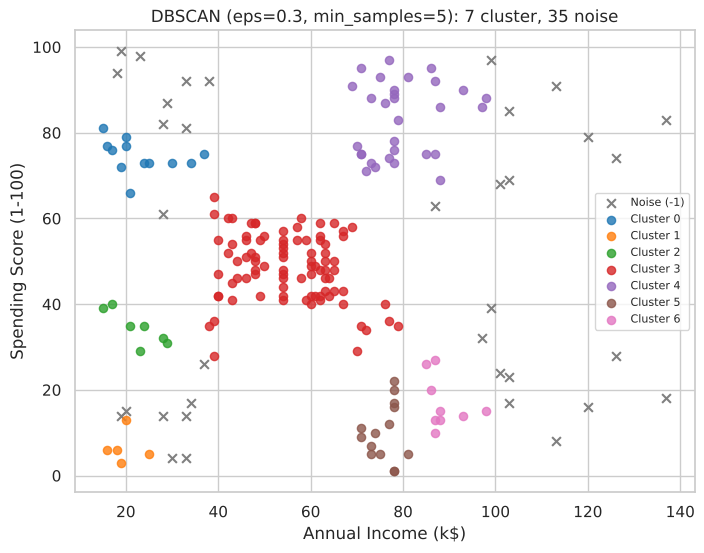

In [10]:
def plot_clusters(ax, data, labels, title):
    """Scatter plot cluster; noise (-1) digambar sebagai X abu-abu."""
    palette = sns.color_palette("tab10", 10)
    for lab in sorted(np.unique(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(data.iloc[m, 0], data.iloc[m, 1], c="gray", marker="x", s=40, label="Noise (-1)")
        else:
            ax.scatter(data.iloc[m, 0], data.iloc[m, 1], color=palette[lab % 10], s=35, alpha=0.8, label=f"Cluster {lab}")
    ax.set_title(title)
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.legend(fontsize=8, loc="best")

fig, ax = plt.subplots(figsize=(8, 6))
plot_clusters(ax, X, labels_dbscan,
              f"DBSCAN (eps=0.3, min_samples=5): {n_clusters_dbscan} cluster, {n_noise_dbscan} noise")
plt.show()

,eps,min_samples,n_cluster,n_noise,pct_noise,silhouette
0,0.2,3,13,44,22.0,0.470
1,0.2,5,7,77,38.5,0.586
2,0.2,8,2,116,58.0,0.603
3,0.2,10,1,129,64.5,NaN
4,0.3,3,9,14,7.0,0.472
5,0.3,5,7,35,17.5,0.524
6,0.3,8,5,72,36.0,0.593
7,0.3,10,4,88,44.0,0.607
8,0.4,3,4,10,5.0,0.395
9,0.4,5,4,15,7.5,0.478



Kombinasi DBSCAN terpilih: eps=0.4, min_samples=8


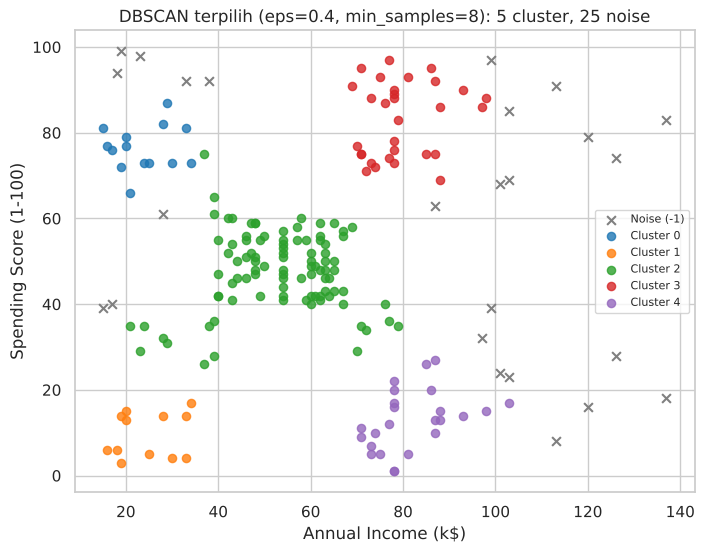

In [11]:
eps_list = [0.2, 0.3, 0.4, 0.5, 0.6, 0.8]
min_samples_list = [3, 5, 8, 10]

rows = []
for eps in eps_list:
    for ms in min_samples_list:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        k = len(set(lab)) - (1 if -1 in lab else 0)
        n_noise = int((lab == -1).sum())
        mask = lab != -1
        # Silhouette hanya valid jika >= 2 cluster pada titik non-noise
        sil = silhouette_score(X_scaled[mask], lab[mask]) if k >= 2 else np.nan
        rows.append({"eps": eps, "min_samples": ms, "n_cluster": k,
                     "n_noise": n_noise, "pct_noise": round(100 * n_noise / len(lab), 1),
                     "silhouette": round(sil, 3) if not np.isnan(sil) else np.nan})

dbscan_grid = pd.DataFrame(rows)
display(dbscan_grid)

# Pilih parameter terbaik: silhouette tertinggi dengan syarat >= 3 cluster dan noise <= 15%
kandidat = dbscan_grid[(dbscan_grid["n_cluster"] >= 3) & (dbscan_grid["pct_noise"] <= 15)].dropna(subset=["silhouette"])
terbaik = kandidat.sort_values("silhouette", ascending=False).iloc[0]
best_eps, best_ms = float(terbaik["eps"]), int(terbaik["min_samples"])
print(f"\nKombinasi DBSCAN terpilih: eps={best_eps}, min_samples={best_ms}")

labels_dbscan_best = DBSCAN(eps=best_eps, min_samples=best_ms).fit_predict(X_scaled)
n_cl_best = len(set(labels_dbscan_best)) - (1 if -1 in labels_dbscan_best else 0)
n_noise_best = int((labels_dbscan_best == -1).sum())

fig, ax = plt.subplots(figsize=(8, 6))
plot_clusters(ax, X, labels_dbscan_best,
              f"DBSCAN terpilih (eps={best_eps}, min_samples={best_ms}): {n_cl_best} cluster, {n_noise_best} noise")
plt.show()

### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

**Jawaban (berdasarkan tabel eksperimen):**

- **Pengaruh `eps`:** semakin besar `eps`, semakin sedikit titik noise dan cluster-cluster saling bergabung. Pada `min_samples=5`, `eps=0,2` menghasilkan 7 cluster dengan 77 noise (38,5%), `eps=0,3` menghasilkan 7 cluster dengan 35 noise, `eps=0,4` menghasilkan 4 cluster dengan 15 noise, `eps=0,5` menghasilkan 2 cluster dengan 8 noise, dan mulai `eps=0,6` hanya tersisa 1 cluster.
- **Pengaruh `min_samples`:** semakin besar `min_samples`, semakin ketat syarat kepadatan sehingga jumlah noise naik. Pada `eps=0,4`, noise naik dari 10 titik (`min_samples=3`) menjadi 15 (5), 25 (8), dan 51 (10). Jumlah cluster juga bisa berubah karena cluster kecil yang tidak cukup padat berubah menjadi noise.
- **Kombinasi bermasalah:** (1) *terlalu banyak noise*: `eps=0,2` dengan `min_samples=10` menghasilkan hanya 1 cluster dengan 129 noise (64,5%), dan `eps=0,2` dengan `min_samples=8` membuang 116 titik (58%); (2) *satu cluster besar*: semua kombinasi dengan `eps` 0,6 dan 0,8 menghasilkan 1 cluster, karena jarak antar kelompok yang ada lebih kecil dari `eps` sehingga semuanya menyatu. Nilai awal `eps=0,3`, `min_samples=5` menghasilkan 7 cluster dengan 35 noise (17,5%), yang masih membuang terlalu banyak titik dan memecah kelompok menjadi bagian-bagian kecil.
- **Catatan penting tentang silhouette:** silhouette tertinggi pada tabel (sekitar 0,60) justru muncul pada kombinasi yang membuang 44% sampai 58% data sebagai noise, karena silhouette hanya dihitung pada titik non-noise. Karena itu silhouette tidak boleh dipakai sendirian untuk memilih parameter DBSCAN. Pada notebook ini, parameter dipilih dengan silhouette tertinggi dengan syarat minimal 3 cluster dan noise maksimal 15% data, sehingga terpilih **`eps=0,4` dan `min_samples=8`**: 5 cluster, 25 noise (12,5%), silhouette 0,549.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)

print("Jumlah subcluster di pohon CF :", len(birch.subcluster_centers_))
print("Label unik BIRCH              :", np.unique(labels_birch))

Jumlah subcluster di pohon CF : 10
Label unik BIRCH              : [0 1 2 3 4]


In [13]:
print("Jumlah anggota tiap cluster BIRCH:")
print(pd.Series(labels_birch).value_counts().sort_index())
print("\nJumlah cluster terbentuk:", len(np.unique(labels_birch)))

Jumlah anggota tiap cluster BIRCH:
0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64

Jumlah cluster terbentuk: 5


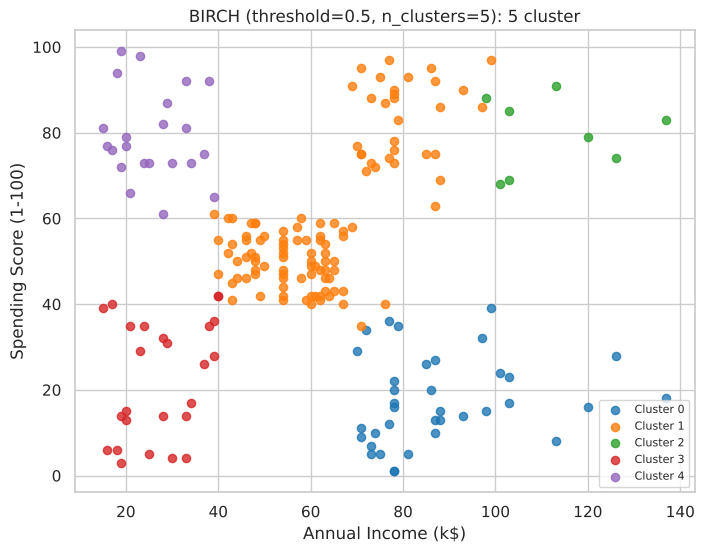

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_clusters(ax, X, labels_birch,
              f"BIRCH (threshold=0.5, n_clusters=5): {len(np.unique(labels_birch))} cluster")
plt.show()

Pengaruh threshold (n_clusters=5):


,threshold,n_clusters (param),n_subcluster,n_cluster_akhir,silhouette
0,0.3,5,23,5,0.478
1,0.5,5,10,5,0.414
2,0.7,5,6,5,0.421
3,1.0,5,4,4,0.389



Tanpa n_clusters (label = subcluster):


,threshold,n_clusters (param),n_cluster_akhir,silhouette
0,0.3,None,23,0.414
1,0.5,None,10,0.477
2,0.7,None,6,0.486
3,1.0,None,4,0.389



Pengaruh n_clusters (threshold=0.3):


,threshold,n_clusters (param),n_cluster_akhir,silhouette
0,0.3,3,3,0.467
1,0.3,4,4,0.494
2,0.3,5,5,0.478
3,0.3,6,6,0.543
4,0.3,7,7,0.539



Threshold BIRCH terpilih: 0.3


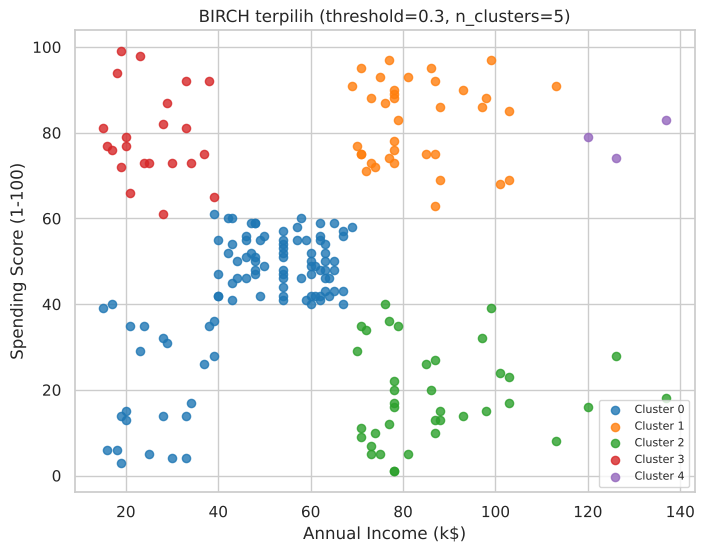

In [15]:
thresholds = [0.3, 0.5, 0.7, 1.0]

rows = []
for t in thresholds:
    m = Birch(threshold=t, n_clusters=5).fit(X_scaled)
    lab = m.labels_
    k = len(np.unique(lab))
    rows.append({"threshold": t, "n_clusters (param)": 5, "n_subcluster": len(m.subcluster_centers_),
                 "n_cluster_akhir": k,
                 "silhouette": round(silhouette_score(X_scaled, lab), 3) if k >= 2 else np.nan})
birch_grid = pd.DataFrame(rows)
print("Pengaruh threshold (n_clusters=5):")
display(birch_grid)

# Tanpa n_clusters (hasil = subcluster dari pohon CF) vs n_clusters ditentukan
rows = []
for t in thresholds:
    m = Birch(threshold=t, n_clusters=None).fit(X_scaled)
    k = len(np.unique(m.labels_))
    rows.append({"threshold": t, "n_clusters (param)": None, "n_cluster_akhir": k,
                 "silhouette": round(silhouette_score(X_scaled, m.labels_), 3) if 2 <= k < len(X_scaled) else np.nan})
print("\nTanpa n_clusters (label = subcluster):")
display(pd.DataFrame(rows))

rows = []
for nc in [3, 4, 5, 6, 7]:
    lab = Birch(threshold=0.3, n_clusters=nc).fit_predict(X_scaled)
    rows.append({"threshold": 0.3, "n_clusters (param)": nc, "n_cluster_akhir": len(np.unique(lab)),
                 "silhouette": round(silhouette_score(X_scaled, lab), 3)})
print("\nPengaruh n_clusters (threshold=0.3):")
display(pd.DataFrame(rows))

# Pilih threshold terbaik (silhouette tertinggi, n_clusters=5)
best_thr = float(birch_grid.sort_values("silhouette", ascending=False).iloc[0]["threshold"])
labels_birch_best = Birch(threshold=best_thr, n_clusters=5).fit_predict(X_scaled)
print(f"\nThreshold BIRCH terpilih: {best_thr}")

fig, ax = plt.subplots(figsize=(8, 6))
plot_clusters(ax, X, labels_birch_best, f"BIRCH terpilih (threshold={best_thr}, n_clusters=5)")
plt.show()

### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

**Jawaban (berdasarkan tabel eksperimen):**

- **Pengaruh `threshold`:** semakin besar `threshold`, semakin sedikit subcluster yang dibentuk pohon CF: 23 subcluster pada `threshold=0,3`, 10 pada 0,5, 6 pada 0,7, dan 4 pada 1,0. Jika `n_clusters=None`, label akhir sama dengan subcluster tersebut sehingga jumlah cluster langsung mengikuti `threshold`. Jika `n_clusters=5`, jumlah cluster akhir tetap 5 selama jumlah subcluster masih lebih banyak dari 5; pada `threshold=1,0` hanya ada 4 subcluster sehingga cluster akhir tidak bisa mencapai 5 (hanya 4).
- **BIRCH vs DBSCAN pada titik yang jauh:** DBSCAN secara eksplisit menandai titik yang tidak padat sebagai noise (label -1), sedangkan BIRCH tidak punya konsep noise dan selalu memasukkan setiap titik ke salah satu cluster. Pada hasil terpilih, tiga pelanggan berpendapatan sangat tinggi (median 126 k$) dijadikan satu cluster kecil sendiri oleh BIRCH, sedangkan DBSCAN menyisihkan titik-titik tepi seperti itu sebagai noise.
- **Pengaruh `n_clusters`:** ya, hasil berubah. Dengan `threshold=0,3`, silhouette untuk `n_clusters` = 3, 4, 5, 6, 7 adalah 0,467; 0,494; 0,478; 0,543; dan 0,539. `n_clusters` menentukan langkah pengelompokan global (agglomerative) terhadap subcluster, sehingga bisa menggabungkan atau memisahkan kelompok.
- **Catatan:** `threshold=0,3` terpilih karena silhouette tertinggi (0,478), tetapi hasilnya kurang seimbang: ukuran clusternya 101, 36, 38, 22, dan 3. Kelompok pendapatan rendah dengan spending rendah ikut tergabung ke cluster tengah, dan satu cluster hanya berisi 3 titik. Jadi skor silhouette yang lebih baik tidak otomatis berarti segmentasi yang lebih berguna.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)

print("EM konvergen        :", gmm.converged_)
print("Jumlah iterasi EM   :", gmm.n_iter_)
print("Bobot komponen      :", np.round(gmm.weights_, 3))

EM konvergen        : True
Jumlah iterasi EM   : 5
Bobot komponen      : [0.413 0.197 0.104 0.166 0.121]


In [17]:
print("Jumlah anggota tiap cluster GMM:")
print(pd.Series(labels_gmm).value_counts().sort_index())

proba = gmm.predict_proba(X_scaled)
proba_df = pd.DataFrame(proba, columns=[f"P(komp {k})" for k in range(proba.shape[1])]).round(3)
proba_df["label"] = labels_gmm
print("\nBeberapa baris probabilitas keanggotaan:")
display(proba_df.head(10))

# Titik dengan keanggotaan relatif tidak pasti: probabilitas maksimum < 0.9
max_proba = proba.max(axis=1)
tidak_pasti = np.where(max_proba < 0.9)[0]
print(f"\nTitik dengan probabilitas maksimum < 0.9: {len(tidak_pasti)} dari {len(proba)}")
print(f"Probabilitas maksimum minimum: {max_proba.min():.3f}, rata-rata: {max_proba.mean():.3f}")
tmp = pd.concat([X.iloc[tidak_pasti], proba_df.iloc[tidak_pasti]], axis=1).assign(max_proba=max_proba[tidak_pasti].round(3))
display(tmp.sort_values("max_proba").head(10))

Jumlah anggota tiap cluster GMM:
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

Beberapa baris probabilitas keanggotaan:


,P(komp 0),P(komp 1),P(komp 2),P(komp 3),P(komp 4),label
0,0.000,0.0,0.001,0.0,0.999,4
1,0.000,0.0,1.000,0.0,0.000,2
2,0.000,0.0,0.000,0.0,1.000,4
3,0.000,0.0,1.000,0.0,0.000,2
4,0.000,0.0,0.002,0.0,0.998,4
5,0.000,0.0,1.000,0.0,0.000,2
6,0.000,0.0,0.000,0.0,1.000,4
7,0.000,0.0,1.000,0.0,0.000,2
8,0.000,0.0,0.000,0.0,1.000,4
9,0.001,0.0,0.998,0.0,0.000,2



Titik dengan probabilitas maksimum < 0.9: 8 dari 200
Probabilitas maksimum minimum: 0.503, rata-rata: 0.983


,Annual Income (k$),Spending Score (1-100),P(komp 0),P(komp 1),P(komp 2),P(komp 3),P(komp 4),label,max_proba
124,70,29,0.497,0.000,0.000,0.503,0.000,3,0.503
48,40,42,0.611,0.000,0.000,0.000,0.388,0,0.611
49,40,42,0.611,0.000,0.000,0.000,0.388,0,0.611
27,28,61,0.279,0.000,0.675,0.000,0.046,2,0.675
160,79,35,0.772,0.000,0.000,0.228,0.000,0,0.772
55,43,41,0.796,0.000,0.000,0.000,0.204,0,0.796
45,39,65,0.822,0.007,0.157,0.000,0.014,0,0.822
47,40,47,0.891,0.000,0.001,0.000,0.108,0,0.891


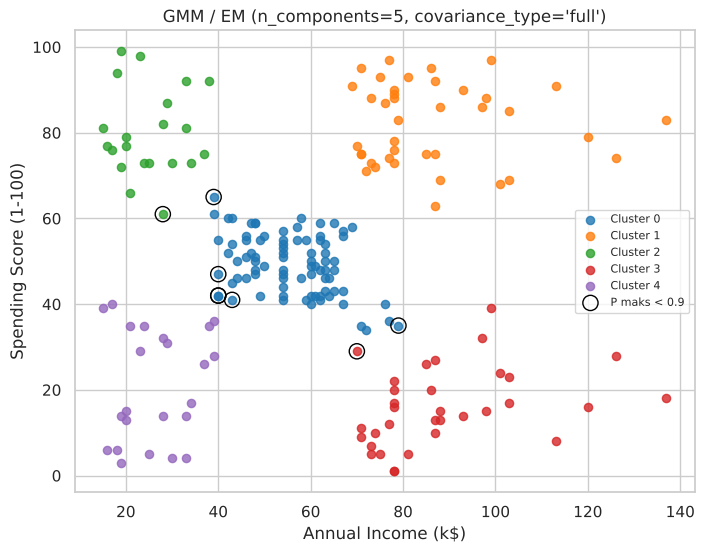

In [18]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_clusters(ax, X, labels_gmm, "GMM / EM (n_components=5, covariance_type='full')")
# Tandai titik dengan keanggotaan tidak pasti
ax.scatter(X.iloc[tidak_pasti, 0], X.iloc[tidak_pasti, 1], facecolors="none", edgecolors="black", s=120, label="P maks < 0.9")
ax.legend(fontsize=8)
plt.show()

,n_components,silhouette,BIC,AIC
0,2,0.379,1153.9,1117.6
1,3,0.430,1151.7,1095.6
2,4,0.413,1103.8,1027.9
3,5,0.554,1058.7,963.0
4,6,0.517,1074.7,959.2
5,7,0.509,1087.3,952.1
6,8,0.430,1102.4,947.3


n_components dengan silhouette tertinggi: 5
n_components dengan BIC terendah        : 5


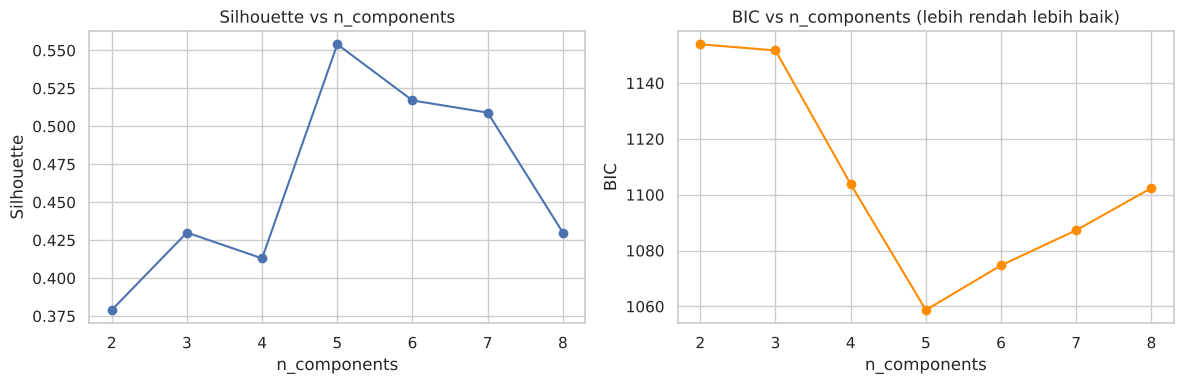

In [19]:
rows = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type="full", random_state=42).fit(X_scaled)
    lab = g.predict(X_scaled)
    rows.append({"n_components": k, "silhouette": round(silhouette_score(X_scaled, lab), 3),
                 "BIC": round(g.bic(X_scaled), 1), "AIC": round(g.aic(X_scaled), 1)})
gmm_grid = pd.DataFrame(rows)
display(gmm_grid)

k_sil = int(gmm_grid.loc[gmm_grid["silhouette"].idxmax(), "n_components"])
k_bic = int(gmm_grid.loc[gmm_grid["BIC"].idxmin(), "n_components"])
print(f"n_components dengan silhouette tertinggi: {k_sil}")
print(f"n_components dengan BIC terendah        : {k_bic}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(gmm_grid["n_components"], gmm_grid["silhouette"], marker="o")
axes[0].set_title("Silhouette vs n_components")
axes[0].set_xlabel("n_components"); axes[0].set_ylabel("Silhouette")
axes[1].plot(gmm_grid["n_components"], gmm_grid["BIC"], marker="o", color="darkorange")
axes[1].set_title("BIC vs n_components (lebih rendah lebih baik)")
axes[1].set_xlabel("n_components"); axes[1].set_ylabel("BIC")
plt.tight_layout()
plt.show()

# Model GMM terbaik (BIC terendah; dicek bersama silhouette dan visualisasi)
gmm_best = GaussianMixture(n_components=k_bic, covariance_type="full", random_state=42).fit(X_scaled)
labels_gmm_best = gmm_best.predict(X_scaled)

### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

**Jawaban (berdasarkan output):**

- **Arti probabilitas keanggotaan:** `predict_proba` memberikan peluang bahwa suatu titik dibangkitkan oleh masing-masing komponen Gaussian (jumlahnya 1 untuk setiap titik). Ini adalah *soft clustering*: label akhir hanya komponen dengan peluang terbesar. Pada model 5 komponen, rata-rata probabilitas maksimum adalah 0,983, artinya sebagian besar titik sangat pasti. Hanya 8 dari 200 titik yang probabilitas maksimumnya di bawah 0,9. Contohnya pelanggan dengan pendapatan 70 dan spending 29 (probabilitas 0,497 vs 0,503 antara dua komponen), yang berada di perbatasan cluster tengah dan cluster berpendapatan tinggi dengan spending rendah.
- **Pengaruh `n_components`:** silhouette dan BIC berubah. Silhouette: 0,379 (k=2), 0,430 (3), 0,413 (4), **0,554 (5)**, 0,517 (6), 0,509 (7), 0,430 (8). BIC: 1153,9; 1151,7; 1103,8; **1058,7**; 1074,7; 1087,3; 1102,4. Terlalu sedikit komponen menggabungkan kelompok yang berbeda, sedangkan terlalu banyak komponen memecah kelompok yang sebenarnya satu (BIC naik karena penalti kompleksitas). AIC terus turun hingga k=8 (947,3), karena penaltinya lebih lemah, sehingga BIC lebih dapat diandalkan di sini.
- **Mengapa jumlah cluster harus ditentukan di awal:** EM mengestimasi parameter (bobot, mean, kovarians) untuk sejumlah komponen tertentu; jumlah komponen menentukan ukuran model sehingga harus ditetapkan sebelum pelatihan. Likelihood akan selalu naik jika komponen ditambah, jadi jumlah yang tepat dipilih dengan melatih beberapa model dan membandingkannya dengan kriteria seperti BIC, silhouette, dan visualisasi.
- **Silhouette tertinggi vs BIC terendah:** pada eksperimen ini keduanya sepakat, yaitu `n_components=5`. Hal ini tidak dijamin terjadi pada dataset lain.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
def evaluasi(X_data, labels, exclude_noise=True):
    """Hitung metrik internal. Noise (-1) dikeluarkan jika exclude_noise=True.
    Metrik hanya dihitung jika ada >= 2 cluster dan n_cluster < n_titik."""
    labels = np.asarray(labels)
    X_arr = np.asarray(X_data)
    n_noise = int((labels == -1).sum())
    if exclude_noise:
        mask = labels != -1
        X_arr, labels_eval = X_arr[mask], labels[mask]
    else:
        labels_eval = labels
    n_cluster = len(np.unique(labels_eval))
    hasil = {"jumlah_cluster": n_cluster, "jumlah_noise": n_noise,
             "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    if n_cluster >= 2 and n_cluster < len(labels_eval):
        hasil["silhouette"] = silhouette_score(X_arr, labels_eval)
        hasil["davies_bouldin"] = davies_bouldin_score(X_arr, labels_eval)
        hasil["calinski_harabasz"] = calinski_harabasz_score(X_arr, labels_eval)
    return hasil

# Uji singkat fungsi
print(evaluasi(X_scaled, labels_dbscan_best))

{'jumlah_cluster': 5, 'jumlah_noise': 25, 'silhouette': 0.5489916076416773, 'davies_bouldin': 0.5014647059705599, 'calinski_harabasz': 222.06509294122455}


In [21]:
hasil_eval = pd.DataFrame({
    f"DBSCAN (eps={best_eps}, min_samples={best_ms})": evaluasi(X_scaled, labels_dbscan_best, exclude_noise=True),
    f"BIRCH (threshold={best_thr}, n_clusters=5)": evaluasi(X_scaled, labels_birch_best, exclude_noise=False),
    f"GMM/EM (n_components={k_bic})": evaluasi(X_scaled, labels_gmm_best, exclude_noise=False),
}).T
hasil_eval.index.name = "model"
hasil_eval = hasil_eval.round(3)
display(hasil_eval)

# Sebagai pembanding: DBSCAN dengan noise diperlakukan sebagai satu "cluster" tersendiri
print("Catatan: metrik DBSCAN dihitung hanya pada titik non-noise, sehingga tidak sepenuhnya sebanding")
print("dengan BIRCH dan GMM yang mengevaluasi seluruh 200 titik.")
print("DBSCAN, jika noise ikut dihitung (label -1 dianggap satu kelompok):")
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in evaluasi(X_scaled, labels_dbscan_best, exclude_noise=False).items()})

,jumlah_cluster,jumlah_noise,silhouette,davies_bouldin,calinski_harabasz
model,,,,,
"DBSCAN (eps=0.4, min_samples=8)",5.0,25.0,0.549,0.501,222.065
"BIRCH (threshold=0.3, n_clusters=5)",5.0,0.0,0.478,0.648,144.013
GMM/EM (n_components=5),5.0,0.0,0.554,0.576,244.940


Catatan: metrik DBSCAN dihitung hanya pada titik non-noise, sehingga tidak sepenuhnya sebanding
dengan BIRCH dan GMM yang mengevaluasi seluruh 200 titik.
DBSCAN, jika noise ikut dihitung (label -1 dianggap satu kelompok):
{'jumlah_cluster': 6, 'jumlah_noise': 25, 'silhouette': 0.415, 'davies_bouldin': 1.651, 'calinski_harabasz': 69.149}


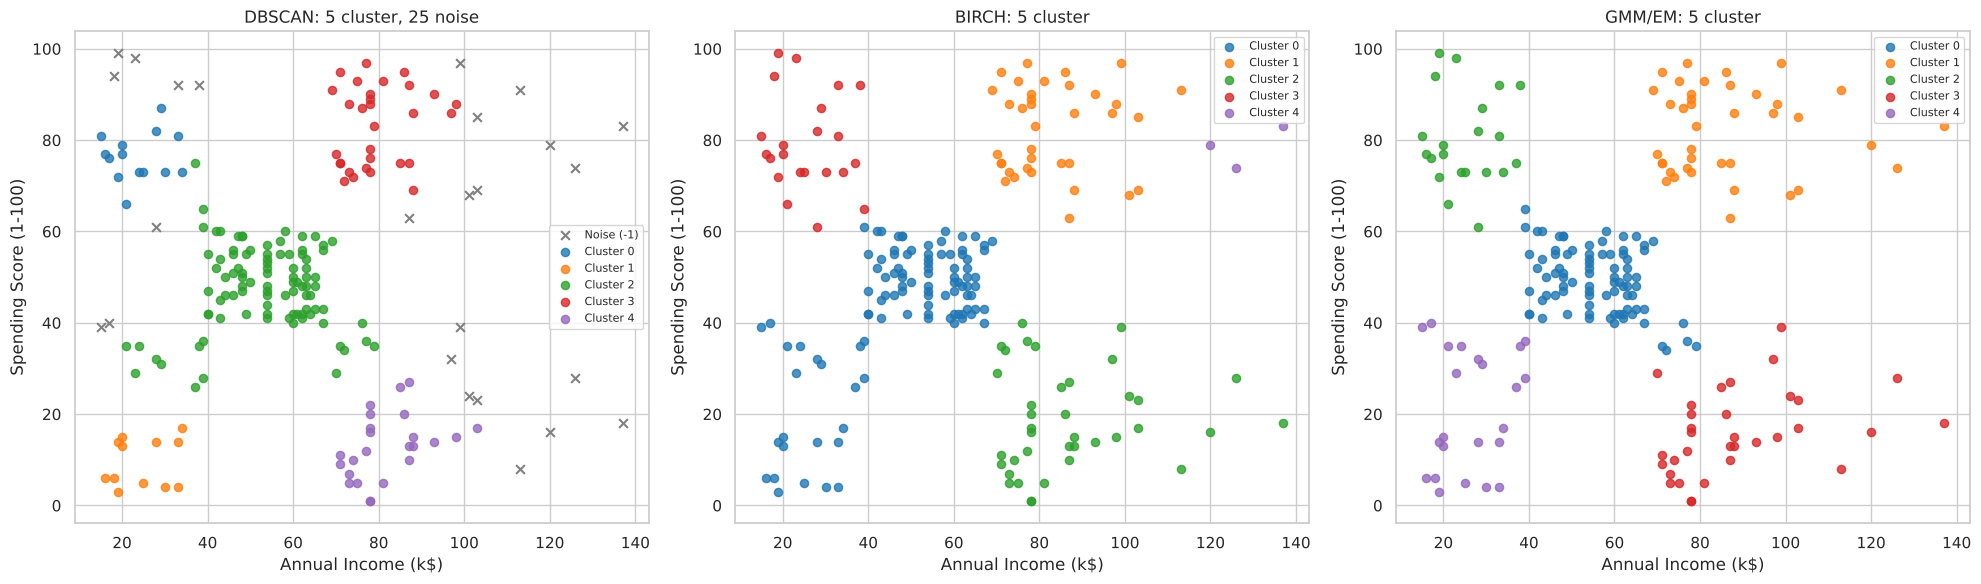

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
plot_clusters(axes[0], X, labels_dbscan_best, f"DBSCAN: {n_cl_best} cluster, {n_noise_best} noise")
plot_clusters(axes[1], X, labels_birch_best, f"BIRCH: {len(np.unique(labels_birch_best))} cluster")
plot_clusters(axes[2], X, labels_gmm_best, f"GMM/EM: {len(np.unique(labels_gmm_best))} cluster")
plt.tight_layout()
plt.show()

In [23]:
def profil(labels, nama):
    d = X.copy()
    d["cluster"] = labels
    out = d.groupby("cluster").agg(
        jumlah=("cluster", "size"),
        income_median=("Annual Income (k$)", "median"),
        income_mean=("Annual Income (k$)", "mean"),
        spending_median=("Spending Score (1-100)", "median"),
        spending_mean=("Spending Score (1-100)", "mean"),
    ).round(1)
    print(f"=== Profil cluster {nama} ===")
    display(out)
    return out

profil_dbscan = profil(labels_dbscan_best, "DBSCAN (cluster -1 = noise)")
profil_birch = profil(labels_birch_best, "BIRCH")
profil_gmm = profil(labels_gmm_best, "GMM/EM")

# Tambahan interpretasi: komposisi Gender per cluster GMM (Gender tidak dipakai sebagai input model)
print("Komposisi Gender per cluster GMM (proporsi):")
display(pd.crosstab(labels_gmm_best, df["Gender"], normalize="index").round(2))
print("Rata-rata Age per cluster GMM:")
display(df.groupby(labels_gmm_best)["Age"].mean().round(1).to_frame("Age_mean"))

=== Profil cluster DBSCAN (cluster -1 = noise) ===


,jumlah,income_median,income_mean,spending_median,spending_mean
cluster,,,,,
-1,25,101.0,83.0,68.0,60.5
0,14,22.5,23.6,76.5,76.4
1,12,22.5,24.6,9.5,9.6
2,95,54.0,53.3,48.0,47.8
3,30,78.0,79.5,86.0,83.1
4,24,78.0,81.9,13.0,13.0


=== Profil cluster BIRCH ===


,jumlah,income_median,income_mean,spending_median,spending_mean
cluster,,,,,
0,101,50.0,48.2,47.0,43.4
1,36,78.0,83.1,85.5,82.4
2,38,80.0,87.0,16.5,18.6
3,22,24.5,25.7,77.0,79.4
4,3,126.0,127.7,79.0,78.7


=== Profil cluster GMM/EM ===


,jumlah,income_median,income_mean,spending_median,spending_mean
cluster,,,,,
0,84,55.5,55.6,49.5,49.4
1,39,79.0,86.5,83.0,82.1
2,21,24.0,25.1,77.0,80.0
3,33,86.0,88.8,15.0,16.0
4,23,25.0,26.3,17.0,20.9


Komposisi Gender per cluster GMM (proporsi):


Gender,Female,Male
row_0,,
0,0.60,0.40
1,0.54,0.46
2,0.57,0.43
3,0.45,0.55
4,0.61,0.39


Rata-rata Age per cluster GMM:


,Age_mean
0,42.7
1,32.7
2,25.3
3,40.5
4,45.2


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak. Jumlah cluster muncul dari `eps` dan `min_samples` (pada eksperimen ini 1 sampai 13 cluster tergantung parameter). | Opsional. Jika `n_clusters=None`, jumlah cluster = jumlah subcluster dari `threshold`; jika `n_clusters` diberikan, jumlah cluster akhir ditentukan (selama subcluster cukup banyak). | Ya. `n_components` harus ditentukan sebelum pelatihan (dipilih dengan BIC/silhouette; di sini 5). |
| Dapat memberi label noise secara eksplisit? | Ya, label -1 (25 titik = 12,5% pada hasil terpilih). | Tidak. Semua titik masuk suatu cluster. | Tidak secara eksplisit, tetapi probabilitas keanggotaan rendah (di sini 8 titik < 0,9) menandai titik yang ambigu. |
| Parameter yang paling memengaruhi hasil | `eps` (pada `min_samples` tetap, `eps` 0,2 sampai 0,6 mengubah hasil dari 7 cluster menjadi 1 cluster) dan `min_samples` (menaikkan noise). | `threshold` (jumlah subcluster 23 sampai 4) dan `n_clusters`. | `n_components` (silhouette 0,379 sampai 0,554) dan `covariance_type`. |
| Bentuk cluster yang dapat dimodelkan | Bentuk sembarang yang dibatasi kepadatan. | Cenderung bulat/kompak, karena berbasis ringkasan centroid dan jarak. | Elips (dengan `covariance_type='full'`), dengan ukuran dan orientasi yang bisa berbeda. |
| Kelebihan | Dapat mendeteksi outlier; tidak perlu jumlah cluster; bentuk bebas. | Cepat dan hemat memori, cocok untuk data besar; bisa diproses bertahap. | Memberi probabilitas keanggotaan (soft clustering); metrik terbaik pada eksperimen ini (silhouette 0,554; Calinski-Harabasz 244,9); jumlah komponen dapat dipilih dengan BIC. |
| Kekurangan | Sangat sensitif terhadap `eps` dan `min_samples`; sulit jika kepadatan antar cluster berbeda; bisa membuang banyak data sebagai noise. | Tidak mengenali noise; hasil dipengaruhi urutan data dan `threshold`; pada eksperimen ini menghasilkan cluster tidak seimbang (101, 36, 38, 22, 3). | Perlu menentukan jumlah komponen; mengasumsikan data berdistribusi Gaussian; bisa terjebak pada optimum lokal (bergantung inisialisasi). |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

---

**1. Scaling.** DBSCAN (`eps`) dan BIRCH (`threshold`) bekerja berdasarkan jarak Euclidean, sedangkan GMM menaksir kovarians; semuanya mengasumsikan fitur berada pada skala yang sebanding. Fitur dengan rentang atau variansi lebih besar akan mendominasi jarak. Pada dataset ini kebetulan kedua fitur sudah berskala mirip (rentang 122 dan 98; standar deviasi 26,26 dan 25,82), sehingga bentuk sebaran pada scatter plot sebelum dan sesudah scaling hampir sama. Meski begitu scaling tetap diperlukan sebagai praktik yang benar, dan membuat nilai `eps` serta `threshold` bermakna dalam satuan standar deviasi (misalnya `eps=0,4` berarti 0,4 standar deviasi) serta independen dari satuan asli fitur.

**2. Parameter DBSCAN.** Menaikkan `eps` mengurangi noise tetapi menggabungkan cluster: pada `min_samples=5`, 7 cluster dengan 77 noise (`eps=0,2`) menjadi 7 cluster dengan 35 noise (0,3), 4 cluster dengan 15 noise (0,4), 2 cluster dengan 8 noise (0,5), dan 1 cluster pada `eps` 0,6 ke atas. Menaikkan `min_samples` menaikkan noise (pada `eps=0,4`: 10, 15, 25, 51 noise untuk `min_samples` 3, 5, 8, 10). Parameter terpilih `eps=0,4` dan `min_samples=8` memberi 5 cluster dengan 25 noise.

**3. Parameter BIRCH.** `threshold` yang lebih besar menghasilkan lebih sedikit subcluster (23, 10, 6, 4 untuk 0,3; 0,5; 0,7; 1,0). `n_clusters` menentukan jumlah cluster akhir dengan mengelompokkan subcluster tersebut; pada `threshold=0,3`, silhouette berubah dari 0,467 (3 cluster) sampai 0,543 (6 cluster). Dengan `n_clusters=5`, `threshold=1,0` hanya menghasilkan 4 cluster karena subcluster-nya tidak cukup.

**4. Probabilitas GMM dan EM.** Probabilitas keanggotaan (responsibility) adalah peluang suatu titik berasal dari tiap komponen Gaussian. Pada langkah *E (Expectation)*, EM menghitung responsibility ini dengan parameter saat ini; pada langkah *M (Maximization)*, EM memperbarui bobot, mean, dan kovarians setiap komponen menggunakan responsibility sebagai bobot titik. Kedua langkah diulang sampai konvergen (pada eksperimen ini konvergen dalam 5 iterasi). Hasilnya: 5 komponen dengan bobot sekitar 0,41; 0,20; 0,10; 0,17; 0,12, dan rata-rata probabilitas maksimum 0,983.

**5. Model paling mudah diinterpretasikan.** Menurut saya GMM/EM dengan 5 komponen. Setiap pelanggan mendapat label (tidak ada noise yang tak terklasifikasi), kelima cluster berukuran masuk akal (84, 39, 21, 33, 23) dan sesuai dengan lima kelompok yang terlihat pada scatter plot awal, ditambah probabilitas yang menunjukkan seberapa pasti suatu pelanggan masuk ke cluster tertentu. DBSCAN terpilih juga mudah dibaca (5 cluster yang hampir identik), tetapi 25 pelanggan (12,5%) tidak mendapat segmen. BIRCH paling sulit diinterpretasikan karena ukuran clusternya timpang dan ada cluster berisi hanya 3 pelanggan.

**6. Konsistensi metrik.** Tidak sepenuhnya sama. Silhouette dan Calinski-Harabasz tertinggi pada GMM (0,554 dan 244,9), tetapi Davies-Bouldin terendah pada DBSCAN (0,501 vs 0,576 pada GMM). BIRCH terendah pada ketiga metrik (silhouette 0,478; DB 0,648; CH 144,0). Selisih silhouette DBSCAN dan GMM sangat kecil (0,549 vs 0,554). Kemungkinan penyebabnya: (a) metrik DBSCAN dihitung hanya pada 175 titik non-noise, sedangkan GMM dan BIRCH pada seluruh 200 titik, jadi tidak sepenuhnya sebanding (jika noise ikut dihitung sebagai satu kelompok, silhouette DBSCAN turun menjadi 0,415 dan DB naik menjadi 1,651); (b) tiap metrik mengukur aspek berbeda (kekompakan dan keterpisahan vs rasio sebaran dalam dan antar cluster); (c) metrik-metrik ini cenderung menyukai cluster yang bulat dan kompak.

**7. Karakteristik cluster (GMM, median pada fitur asli).**

| Cluster | Jumlah | Median income (k$) | Median spending | Nama deskriptif |
|---|---|---|---|---|
| 0 | 84 | 55,5 | 49,5 | Pelanggan menengah (standar) |
| 1 | 39 | 79,0 | 83,0 | Berpendapatan tinggi, belanja tinggi (target premium) |
| 2 | 21 | 24,0 | 77,0 | Berpendapatan rendah, belanja tinggi (rata-rata usia termuda, 25,3 tahun) |
| 3 | 33 | 86,0 | 15,0 | Berpendapatan tinggi, belanja rendah (potensi yang belum tergarap) |
| 4 | 23 | 25,0 | 17,0 | Berpendapatan rendah, belanja rendah (hemat) |

DBSCAN dan BIRCH menghasilkan pola serupa untuk cluster-cluster di sudut. Noise DBSCAN (25 titik) memiliki median income 101 k$ dan median spending 68, sehingga noise terdiri dari titik-titik tepi, termasuk banyak pelanggan berpendapatan sangat tinggi serta beberapa titik di pinggir kelompok berpendapatan rendah (lihat scatter plot). Gender tidak membedakan cluster secara tegas (proporsi perempuan sekitar 0,45 sampai 0,61 di semua cluster GMM).

**8. Keterbatasan.** (a) Hanya dua fitur: `Age` dan `Gender` diabaikan, padahal bisa membedakan perilaku pelanggan (misalnya cluster 2 rata-rata berusia 25 tahun), dan hasil pada 2 dimensi belum tentu berlaku pada ruang fitur yang lebih kaya, termasuk pilihan `eps` yang sangat bergantung pada dimensi. (b) Dataset hanya 200 pelanggan: cluster kecil (21 sampai 39 titik) mudah berubah, hasil DBSCAN sangat sensitif terhadap beberapa titik, dan estimasi kovarians GMM kurang stabil. (c) Tidak ada label sebenarnya, sehingga metrik internal hanya ukuran kualitas relatif, bukan kebenaran. (d) Parameter dipilih pada data yang sama dengan yang dievaluasi, sehingga ada risiko overfitting pada pemilihan parameter. (e) Dataset ini terkenal sebagai data tutorial yang strukturnya sangat bersih, jadi hasil yang bagus belum tentu mencerminkan data pelanggan nyata.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

---

**Algoritma paling berguna.** Untuk dataset ini, **EM/GMM dengan 5 komponen** memberikan hasil paling berguna: silhouette tertinggi (0,554), Calinski-Harabasz tertinggi (244,9), Davies-Bouldin yang baik (0,576), setiap pelanggan mendapat segmen, dan lima segmen yang dihasilkan mudah diberi nama bisnis. DBSCAN terpilih hampir setara (silhouette 0,549; Davies-Bouldin terbaik 0,501) dan berguna terutama karena dapat menandai 25 pelanggan yang tidak masuk pola, tetapi metriknya dihitung tanpa noise sehingga perbandingannya tidak sepenuhnya adil. BIRCH paling lemah pada eksperimen ini (silhouette 0,478) dan hasilnya tidak seimbang.

**Parameter terpilih dan alasannya.**
- GMM: `n_components=5`, `covariance_type='full'`, `random_state=42`. Nilai 5 memiliki silhouette tertinggi dan BIC terendah (1058,7), dan sesuai dengan kelompok yang terlihat pada scatter plot awal.
- DBSCAN: `eps=0,4`, `min_samples=8`. Dipilih dengan silhouette tertinggi dengan syarat minimal 3 cluster dan noise maksimal 15%, karena silhouette tertinggi mentah (sekitar 0,60) berasal dari kombinasi yang membuang 44% sampai 58% data.
- BIRCH: `threshold=0,3`, `n_clusters=5`. Dipilih berdasarkan silhouette tertinggi di antara threshold yang dicoba, walaupun ukuran clusternya timpang (101, 36, 38, 22, 3).

**Perbedaan utama yang dipelajari.** DBSCAN berbasis kepadatan: tidak butuh jumlah cluster dan dapat menandai noise, tetapi sangat sensitif terhadap `eps` dan `min_samples` (hasil berubah dari 7 cluster menjadi 1 cluster hanya dengan menaikkan `eps`). BIRCH merangkum data dalam pohon CF sehingga cepat dan hemat memori untuk data besar, tetapi tidak mengenali noise dan kualitas hasilnya bergantung pada `threshold` dan `n_clusters`. EM/GMM adalah model probabilistik yang memberi soft assignment dan memungkinkan pemilihan jumlah komponen dengan BIC, tetapi mengasumsikan bentuk Gaussian dan jumlah komponen harus ditentukan di awal.

**Eksperimen lanjutan.**
- Menambahkan `Age` (dan `Gender` yang di-encode) sebagai fitur dan membandingkan hasilnya dengan model dua fitur.
- Mencoba `covariance_type` lain pada GMM (`tied`, `diag`, `spherical`) dan memeriksa kestabilan dengan beberapa `random_state`.
- Menentukan `eps` DBSCAN secara lebih terarah dengan grafik k-distance, serta mencoba HDBSCAN.
- Memvalidasi kestabilan cluster dengan resampling (bootstrap) atau pada dataset pelanggan yang lebih besar.
- Mengubah hasil segmentasi menjadi rekomendasi bisnis, misalnya promosi khusus untuk cluster berpendapatan tinggi dengan spending rendah.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)